In [1]:
import numpy as np
import matplotlib.pyplot as plt
from v2_fm_pmssm.data import load_data

#### 1. Read the electroweakino masses, MO_Omega and SP_LSP_type

In [2]:
neutralinos = ['SP_m_chi_10', 'SP_m_chi_20', 'SP_m_chi_30', 'SP_m_chi_40']
charginos = ['SP_m_chi_1p', 'SP_m_chi_2p']
branches = neutralinos + charginos + ['MO_Omega', 'SP_LSP_type', 'SP_m_H']

parameter, parameter_table, point_id, file_names = load_data(param_names=branches, max_files=20)  # max_files=None: all files

---Load pMSSM dataset v2---
Loading files: 20/20
Loaded 20 files from ['/u/yinya/archive/gen_flat_v2/ntuples']
Total samples: 160000


#### 2. Neutralino masses near -1
Invalid results are exactly -1; the valid masses are signed, so they can also be close to -1.

Quick inspection of chi_10 masses

In [9]:
x = parameter[neutralinos[0]]
x

array([  -1.     , -253.89345, -454.63953, ..., -270.35043, -196.18959,
        750.56055], shape=(160000,), dtype=float32)

The closest value to -1

In [10]:
x[np.argmin(np.where(x == -1, np.inf, np.abs(x + 1)))]

np.float32(-0.9998007)

Within the tolerance of 0.01

In [17]:
x_new = x[np.where(np.isclose(x, -1, atol=0.01))]
x_new[np.where(x_new != -1)]

array([-1.0019702, -0.9998007, -1.0045266], dtype=float32)

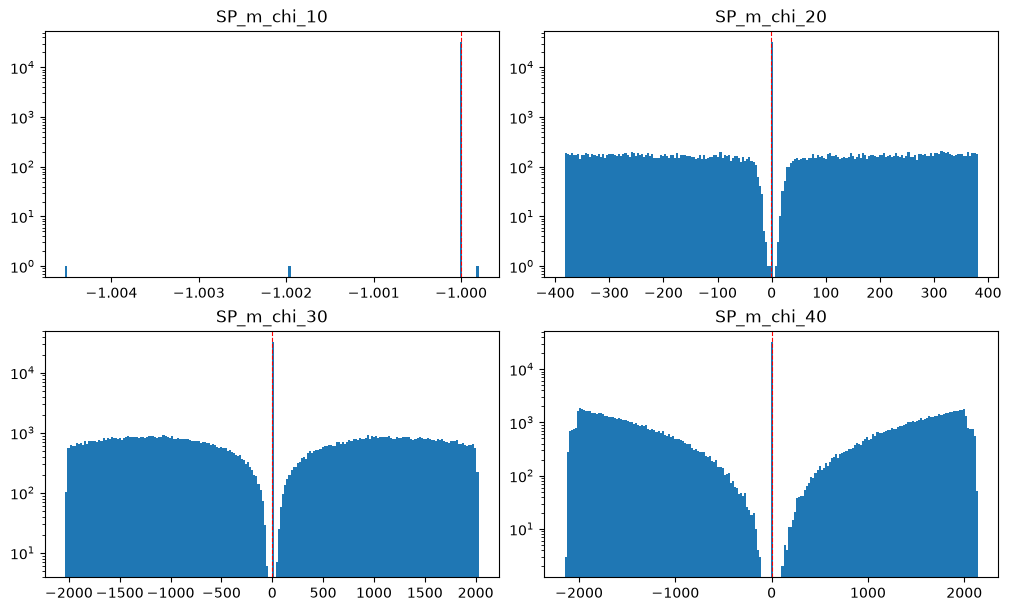

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), constrained_layout=True)

for ax, b in zip(axes.flat, neutralinos):
    x = parameter[b]
    tolerance = abs(-1 - x[np.argmin(np.where(x == -1, np.inf, np.abs(x + 1)))])
    ax.hist(x[np.abs(x + 1) < 100*tolerance], bins=200, log=True)  # only values within 100 * closest distance
    ax.axvline(-1, color='r', ls='--', lw=0.8)
    ax.set_title(b)
plt.show()

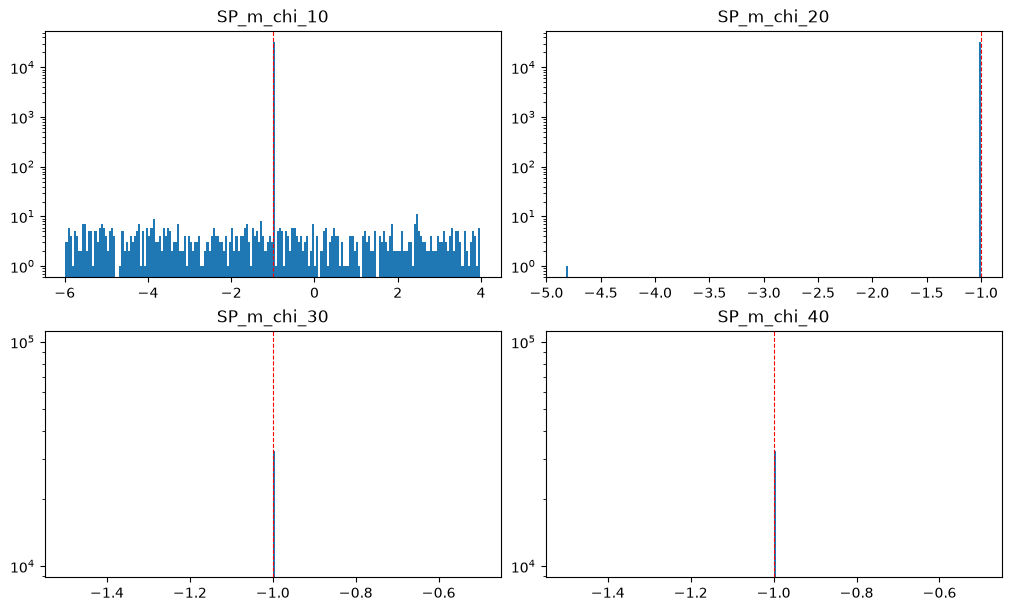

SP_m_chi_10: exactly -1: 32618, closest other value to -1: -0.9998
SP_m_chi_20: exactly -1: 32618, closest other value to -1: -4.8169
SP_m_chi_30: exactly -1: 32618, closest other value to -1: 49.1431
SP_m_chi_40: exactly -1: 32618, closest other value to -1: 111.1996


In [22]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), constrained_layout=True)

for ax, b in zip(axes.flat, neutralinos):
    x = parameter[b]
    ax.hist(x[np.abs(x + 1) < 5], bins=200, log=True)  # only values within 5 GeV of -1
    ax.axvline(-1, color='r', ls='--', lw=0.8)
    ax.set_title(b)
plt.show()

for b in neutralinos:
    x = parameter[b]
    print(f"{b}: exactly -1: {np.sum(x == -1)}, closest other value to -1: {x[np.argmin(np.where(x == -1, np.inf, np.abs(x + 1)))]:.4f}")

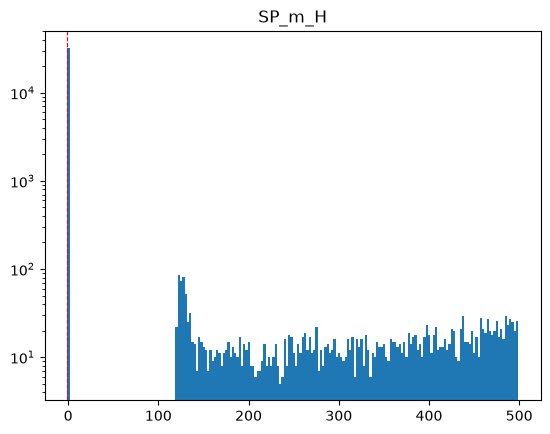

SP_m_H: exactly -1: 32618, closest other value to -1: 119.9995


In [7]:
b = "SP_m_H"
x = parameter[b]
plt.hist(x[np.abs(x + 1) < 500], bins=200, log=True)  # only values within 5 GeV of -1
plt.axvline(-1, color='r', ls='--', lw=0.8)
plt.title(b)
plt.show()

print(f"{b}: exactly -1: {np.sum(x == -1)}, closest other value to -1: {x[np.argmin(np.where(x == -1, np.inf, np.abs(x + 1)))]:.4f}")

#### 3. Do the -1 points correspond?

In [9]:
lsp_invalid = parameter['SP_LSP_type'] == -1

# every electroweakino mass is -1 exactly where SP_LSP_type is -1
for b in neutralinos + charginos:
    print(f"{b}: same -1 points as SP_LSP_type: {np.all((parameter[b] == -1) == lsp_invalid)}")

SP_m_chi_10: same -1 points as SP_LSP_type: True
SP_m_chi_20: same -1 points as SP_LSP_type: True
SP_m_chi_30: same -1 points as SP_LSP_type: True
SP_m_chi_40: same -1 points as SP_LSP_type: True
SP_m_chi_1p: same -1 points as SP_LSP_type: True
SP_m_chi_2p: same -1 points as SP_LSP_type: True


In [10]:
omega_invalid = parameter['MO_Omega'] == -1

print(f"both -1:                    {np.sum(lsp_invalid & omega_invalid)}")
print(f"only SP_LSP_type is -1:     {np.sum(lsp_invalid & ~omega_invalid)}")
print(f"only MO_Omega is -1:        {np.sum(~lsp_invalid & omega_invalid)}")

both -1:                    32618
only SP_LSP_type is -1:     0
only MO_Omega is -1:        24


In [ ]:
higgs_invalid = parameter['SP_m_H'] == -1

print(f"both -1:                    {np.sum(higgs_invalid & omega_invalid)}")
print(f"only SP_m_H is -1:     {np.sum(higgs_invalid & ~omega_invalid)}")
print(f"only MO_Omega is -1:        {np.sum(~higgs_invalid & omega_invalid)}")

both -1:                    32618
only SP_LSP_type is -1:     0
only MO_Omega is -1:        24


In [12]:
print(f"both -1:                    {np.sum(higgs_invalid & lsp_invalid)}")
print(f"only SP_LSP_type is -1:     {np.sum(higgs_invalid & ~lsp_invalid)}")
print(f"only SP_m_H is -1:        {np.sum(~higgs_invalid & lsp_invalid)}")

both -1:                    32618
only SP_LSP_type is -1:     0
only SP_m_H is -1:        0
